# Hackathon project

The whole project, top to bottom: problem, data, baseline, model, evaluation, demo.
Run it with **Restart kernel and run all**. It must pass at every moment.

In [1]:
# Setup: pick up changes to src/ without restarting, and make `import src` work from notebooks/
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "..")
import src

In [2]:
# One seed for everything random, so every run gives the same numbers
import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
print("seed:", SEED)

seed: 42


## Problem
**Who it is for:** the owner of a small UK supplier, deciding whether to give a young company 30 days of credit.

**What goes in and what comes out:** a customer's company number goes in. FLAG, CLEAR or NOT ENOUGH EVIDENCE comes out, with the reason.

**Why it is hard:** after a company goes insolvent, the same people can start again in a new one (a "phoenix"). A matching name is not proof. A common name raises false alarms, and a new officer id on the register hides the real trail.

This project is a prototype and is not financial advice.

> **Where this notebook stands.** Every box below runs on the *tiny world*: 28 hand-made rows with invented names and known answers. That checks that the pipeline works. It is **not a result**. The real Companies House data comes with card #36, and the final numbers with card #45.

## Data
For now the data is the tiny world (`tests/tiny_world.py`). It comes as the same two tables the real data will: **mentions** (one row per company or person, as one record describes them) and **claims** (one row per "this person is a director of this company", with its dates).

In [3]:
import pandas as pd
from src import evidence as ev
from tests.tiny_world import tiny_world

# truth holds the known answers. It checks the pipeline, and it makes the stand-in probabilities
# in the Model section. No real method ever reads it.
mentions, claims, truth = tiny_world()
ev.check_rows(mentions, claims)    # stops here if a row breaks the shared schema
queries = truth["queries"]         # the five companies a supplier asks about

print(mentions["kind"].value_counts().to_dict(), "and", len(claims), "claims")
mentions.loc[mentions["kind"] == "company", ["company_number", "display_name", "incorporated_on", "insolvency_on"]]

{'company': 9, 'person': 9} and 10 claims


,company_number,display_name,incorporated_on,insolvency_on
0,TW000001,Harrow Build Ltd,2017-02-01,2021-03-15
1,TW000002,Harrow Build Services Ltd,2021-04-20,2022-09-01
2,TW000003,Northgate Roofing Ltd,2021-06-01,NaN
3,TW000004,Smith and Sons Joinery Ltd,2015-05-01,2020-10-01
4,TW000005,Elm Street Plumbing Ltd,2021-02-10,NaN
5,TW000006,Quiet Fields Landscaping Ltd,2021-09-01,NaN
6,TW000007,Brightwater Electrical Ltd,2021-05-15,NaN
7,TW000008,Lambert Electrical Ltd,2016-03-01,NaN
8,TW000009,Smith Brothers Builders Ltd,2023-01-10,2024-05-01


**The label and the split.** A company *failed* if, within 24 months of being formed, it went into liquidation or administration or was dissolved (removed from the register). Companies are split by formation date: train on Jan–Sep 2021, validate on Oct–Dec 2021, test on 2022.

In [4]:
from src import evaluate

companies = mentions[mentions["kind"] == "company"].set_index("company_number").loc[queries]
labels = pd.DataFrame({
    "company_id": queries,
    "formed_on": companies["incorporated_on"].to_numpy(),
    "failed": evaluate.label_failures(mentions).loc[queries].to_numpy(),
    "split": None,
}, columns=ev.LABEL_COLS)

# split() gives three tables: write each one's name next to its companies
for name, part in zip(["train", "validation", "test"], evaluate.split(companies)):
    labels.loc[labels["company_id"].isin(part.index), "split"] = name

assert dict(zip(labels["company_id"], labels["failed"])) == truth["failed"]   # the known answers
labels

,company_id,formed_on,failed,split
0,TW000002,2021-04-20,True,train
1,TW000003,2021-06-01,False,train
2,TW000005,2021-02-10,False,train
3,TW000006,2021-09-01,False,train
4,TW000007,2021-05-15,False,train


All five tiny companies were formed between January and September 2021, so they all land in train. The tiny world has no test set.

## Baseline
Three simple rules our method has to beat:
1. **flag_nothing:** never flag. Failures are rare, so this is right most of the time.
2. **same_name:** two directors with the same name are the same person. What someone does by hand.
3. **officer_links:** only the links Companies House already makes through its officer id. What a careful supplier sees on the register today.

A company is flagged when one of its directors is linked to a company that went insolvent in the three years before it was formed.

In [5]:
from src import baseline

baseline_decisions = baseline.run_all(queries, mentions, claims)
table = baseline_decisions.pivot(index="query", columns="method", values="decision")
table["really failed"] = labels.set_index("company_id")["failed"]
table

method,flag_nothing,officer_links,same_name,really failed
query,,,,
TW000002,CLEAR,CLEAR,FLAG,True
TW000003,CLEAR,CLEAR,FLAG,False
TW000005,CLEAR,CLEAR,FLAG,False
TW000006,CLEAR,CLEAR,CLEAR,False
TW000007,CLEAR,CLEAR,CLEAR,False


In [6]:
# Count each baseline's flags against what really happened.
# To do: use evaluate.score_methods() instead once it is on main (card #80).
flagged = baseline_decisions["decision"] == "FLAG"
failed = baseline_decisions["query"].map(labels.set_index("company_id")["failed"])
counts = pd.DataFrame({"flags": flagged, "right flags": flagged & failed,
                       "false flags": flagged & ~failed, "misses": failed & ~flagged})
counts.groupby(baseline_decisions["method"]).sum()

,flags,right flags,false flags,misses
method,,,,
flag_nothing,0,0,0,1
officer_links,0,0,0,1
same_name,3,1,2,0


**What the tiny world shows** (five companies and one real failure, so a check and not a result):
- `flag_nothing` and `officer_links` flag nothing, so both miss the phoenix. The register gave its director a new officer id, and the officer links can't see past that.
- `same_name` catches the phoenix, but it also flags two honest companies whose director shares a name with someone else.

Those two kinds of mistake, the missed phoenix and the false alarm on a shared name, are what our method is meant to avoid.

## Model
A company number goes in. For each of its directors we ask: is this the same person as someone who ran a company that went insolvent earlier? Each possible match gets a probability instead of a yes or no. From those we compute P(predecessor), then P(fail), then the decision.

**Who might be the same person?** Comparing every person record with every other is too many pairs, so a cheap rule proposes the candidates: two person records are a candidate pair when they have the same surname and first initial, or the same birth month and year and a similar surname.

Each candidate pair then gets the numbers the matcher will learn from: how similar the names are, and whether birth month and year, postcode district and nationality agree. A `_missing` column says when a value is unknown, so "unknown" is not mistaken for "different". The register's officer id is never one of these numbers: it is the label the matcher is trained on.

In [7]:
from src import resolve

candidates = resolve.candidate_pairs(mentions)
features = resolve.pair_features(candidates, mentions)

assert set(truth["same_person"]) <= set(zip(candidates["a"], candidates["b"]))   # blocking loses no true pair
people = (mentions["kind"] == "person").sum()
print(len(candidates), "candidate pairs out of", people * (people - 1) // 2, "possible")
features

7 candidate pairs out of 36 possible


,name_similarity,name_missing,birth_same,birth_missing,postcode_same,postcode_missing,nationality_same,nationality_missing
0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
5,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
6,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0


**Learning from the register's own links.** The matcher needs examples with known answers, and the register gives them. Two records with the same officer id are the same person (label 1). A candidate pair with different officer ids counts as two people (label 0). That second label is sometimes wrong: the register can give one person two officer ids, and the tiny world's phoenix is exactly that case.

A logistic regression then learns one weight per feature and gives every pair a number `p` between 0 and 1. Nothing is merged: every pair stays in the table with its `p`.

In [8]:
labelled = resolve.labelled_pairs(mentions)
print("pairs per label:", labelled["label"].value_counts().to_dict())

model = resolve.train_matcher(resolve.pair_features(labelled, mentions), labelled["label"], SEED)
scored = resolve.scored_pairs(model, labelled, mentions)

# The known answers next to the register's label, to see where the label is wrong.
scored["really the same person"] = [pair in truth["same_person"] for pair in zip(scored["a"], scored["b"])]
scored[["label", "p", "really the same person"]]

pairs per label: {0: 5, 1: 2}


,label,p,really the same person
0,1,0.441023,True
1,0,0.169243,False
2,0,0.441023,True
3,0,0.169243,False
4,0,0.169243,False
5,0,0.169243,False
6,1,0.441023,True


In [9]:
resolve.matcher_weights(model).round(2)

name_similarity        0.00
name_missing           0.00
birth_same             0.68
birth_missing          0.00
postcode_same          0.68
postcode_missing       0.00
nationality_same       0.00
nationality_missing    0.00
intercept             -1.59
dtype: float64

**What the tiny world shows** (seven hand-made pairs, so a check that the matcher runs, not a trained model):
- The three pairs that agree on birth month and postcode district get `p` = 0.44. The four look-alikes, which share only a name, get 0.17.
- The row with label 0 that is really the same person is the phoenix. The register's label says "two people", yet the matcher gives it the same `p` as the pairs the register does link, because its features look the same. That is the trail the officer links alone can't see.
- The weights: `birth_same` and `postcode_same` are positive, so agreeing on either makes "same person" more likely. All the others are 0 here, because every tiny pair has the same name and nationality and no value is missing, so those columns can't tell the pairs apart.

The real weights come with the real data (card #36). `p` is only called a probability once it passes the calibration check on validation (card #88).

**P(predecessor).** Each candidate match is a chance that a director is the same person as someone who ran an insolvent earlier company. The chance that at least one match is right is 1 − (1 − p₁)(1 − p₂)…, which assumes the matches are independent: whether one is right tells us nothing about another. That isn't quite true, because a director is only one person; Sunday's one-identity rule fixes it (ADR-004).

In [10]:
from src.decide import p_predecessor

# Two independent 50% matches: the chance both are wrong is 0.5 × 0.5, so at least one is right with 0.75
p_predecessor([0.5, 0.5])

0.75

**One identity per director.** The formula above counts two 50% candidates as 75%. But a director is one person: he can't be both. Rule out "he is both", and three cases remain, equally likely here: he is the first, he is the second, or he is nobody we know. So each candidate gets a third.

In general, each probability is turned into odds, p / (1 − p). Candidate k gets odds_k / (1 + the sum of all odds), and "nobody we know" gets the rest.

In [11]:
from src.infer import one_identity

shares = one_identity([0.5, 0.5])
print("each candidate:      ", [round(share, 3) for share in shares])
print("nobody we know:      ", round(1 - sum(shares), 3))
print("he is one of the two:", round(sum(shares), 3), "(the formula above said 0.75)")

each candidate:       [0.333, 0.333]
nobody we know:       0.333
he is one of the two: 0.667 (the formula above said 0.75)


Why this matters: every extra look-alike takes some of the share. Say only the first candidate ran an insolvent company. Alone at 50%, he gives P(predecessor) = 0.5. Next to one equally likely look-alike with a clean record, that drops to 0.33. A director with a common name has many candidates, so each of them becomes less likely. That is how this rule should cut false flags on common names.

Whether it does is measured on validation (card #92). The decisions below still use the formula: the one-identity rule is not wired into them yet.

**Checking the rule by drawing worlds.** A second way to the same numbers, without the formula. A *world* is one complete guess at who is who: every match is "yes" or "no", each with its own probability. Draw many worlds, throw away those in which the director would be two people at once, and count in the rest how often each candidate is "yes".

In [12]:
from src.infer import sample_worlds

two_candidates = pd.DataFrame([("director", "candidate 1", 0.5, None, "example", None),
                               ("director", "candidate 2", 0.5, None, "example", None)], columns=ev.PAIR_COLS)
worlds = sample_worlds(two_candidates, n=400, seed=SEED)
worlds[["a", "b", "p", "worlds_kept"]]

,a,b,p,worlds_kept
0,director,candidate 1,0.363636,308
1,director,candidate 2,0.314935,308


About a quarter of the 400 worlds are thrown away: the ones in which both matches are "yes". `worlds_kept` counts the rest. In those, each candidate is "yes" in about a third, as the formula says. The two numbers are not exactly 0.333 because the worlds are a sample: a number that rests on about 400 kept worlds is within about ±0.05 of the exact one.

Drawing worlds also covers what the formula can't: two directors who both look like the same earlier person. Its weak spot is a record with many likely candidates. Almost every world then breaks the rule and is thrown away, so `worlds_kept` says how many worlds each number rests on, and the closed form is the one to trust there.

**The decision.** A straight line turns P(predecessor) into P(fail). It is fitted on the training companies: its left end is the failure rate of companies with no insolvent predecessor, its right end the failure rate of companies that surely have one. A company in between gets a rate in between. Three costs then say what to do: a missed case costs 10, a wrong flag 2, asking 1. That gives CLEAR at or below 10%, FLAG at or above 50%, and NOT ENOUGH EVIDENCE in between. A company with no director records is NOT ENOUGH EVIDENCE too.

Each decision also names **the one match to check first**: the match that would change the decision if we knew the truth about it. To find it, each match in turn is treated as certainly wrong, then as certainly right, and the decision is recomputed.

> **Stand-ins.** Seven tiny-world pairs can't train a matcher worth using. So the decision layer below still runs on probabilities **made up by hand** from the tiny world's known answers: 0.9 for a true same-person pair, 0.05 for a look-alike. The failure line is fitted, but on those made-up probabilities and four toy companies. This shows that the decision layer works. It says nothing about how good our method is.

In [13]:
from src import decide

# STAND-INS, made up by hand until the matcher is trained on real data (#36).
pairs = pd.DataFrame(
    [(a, b, 0.9, None, "stand-in", None) for a, b in truth["same_person"]]
    + [(a, b, 0.05, None, "stand-in", None) for a, b in truth["look_alikes"]],
    columns=ev.PAIR_COLS)
costs = (10, 2, 1)    # the team's choice: a missed case, a wrong flag, asking

# Each company's candidate matches, and from them its P(predecessor).
matches = {query: decide.candidate_matches(query, mentions, claims, pairs) for query in queries}
p_predecessors = [decide.company_p_predecessor(matches[query]) for query in queries]

# The failure line, fitted on the training companies. Here that is all five: the tiny world has no other split.
failed = labels.set_index("company_id").loc[queries, "failed"]   # each company's own label, in the queries' order
line = decide.fit_failure_line(p_predecessors, failed)
print("failure rate without an insolvent predecessor:", round(line[0], 2))
print("failure rate with one:", round(line[1], 2))

our_decisions = pd.DataFrame([decide.decide(query, matches[query], line, costs) for query in queries],
                             columns=ev.DECISION_COLS)

assert dict(zip(our_decisions["query"], our_decisions["decision"])) == truth["decision"]   # the known answers
# What would change each decision: the earlier company behind the match to check, and the new decision.
our_decisions["to check"] = [None if one is None else
                             f"{one['predecessor']}: {'same' if one['if_same_person'] else 'not the same'} person -> {one['becomes']}"
                             for one in our_decisions["flip"]]
our_decisions[["query", "decision", "p_predecessor", "p_fail", "to check"]]

failure rate without an insolvent predecessor: 0.0
failure rate with one: 1.0


,query,decision,p_predecessor,p_fail,to check
0,TW000002,FLAG,0.90,0.90,TW000001: not the same person -> CLEAR
1,TW000003,CLEAR,0.05,0.05,TW000001: same person -> FLAG
2,TW000005,CLEAR,0.05,0.05,TW000004: same person -> FLAG
3,TW000006,NOT ENOUGH EVIDENCE,NaN,NaN,NaN
4,TW000007,CLEAR,0.00,0.00,NaN


**What the tiny world shows** (four toy companies with a P(predecessor), so a check that the fit runs, not a result): the fitted line runs from 0 to 1. The closest straight line through these four points ends a little below 0 and a little above 1, so both ends were cut to the range a rate can have. All it says is that the one company with a likely predecessor is the one that failed.

On the real training companies the two ends will be real failure rates (card #36). If the right end came out below the FLAG threshold of 50%, FLAG could never fire. That is checked on validation (card #94).

## Evaluation
_Ours next to the baselines on data the model never saw, and where it fails._

Not yet. So far only the baselines are counted, in the Baseline section above, and only on the tiny world: five companies, one of which failed. Our method joins the table once its probabilities come from the matcher instead of by hand (card #31). The numbers that count come from the 2022 test companies, run once at the end (card #45).

### The figures (cards #107, #108)
Three pictures, made by functions in `src/interface.py`, so they redraw by themselves once the notebook runs on the real slice (#170). **For now they show the tiny world: a check that each figure draws what its table says, not a result.**

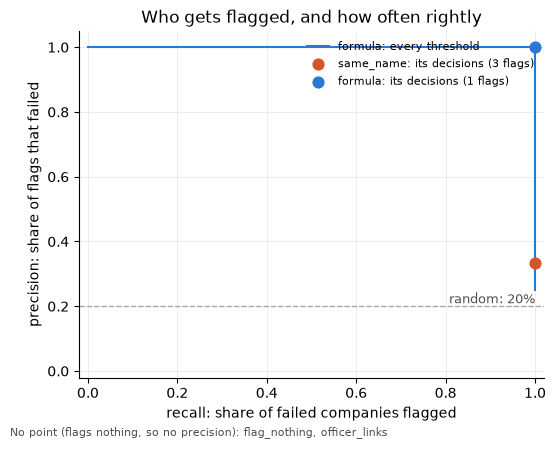

,method,companies,failed,flags,false_flags,misses,precision,recall,not_enough_evidence,pr_auc
0,flag_nothing,5,1,0,0,1,NaN,0.0,0.0,NaN
1,same_name,5,1,3,2,0,0.333333,1.0,0.0,NaN
2,officer_links,5,1,0,0,1,NaN,0.0,0.0,NaN
3,formula,5,1,1,0,0,1.000000,1.0,0.2,1.0


In [14]:
# 107: precision against recall. Ours as a curve over every threshold of p_fail, each method's decisions as a point.
from src import interface

all_decisions = pd.concat([baseline_decisions, our_decisions], ignore_index=True)
scores = evaluate.score_methods(all_decisions, labels)
interface.display_png(interface.pr_figure(all_decisions, labels, scores))
scores

*Precision is the share of flags that really failed; recall is the share of failures that got flagged. Up and to the right is better. The dashed line is what flagging at random gives.*

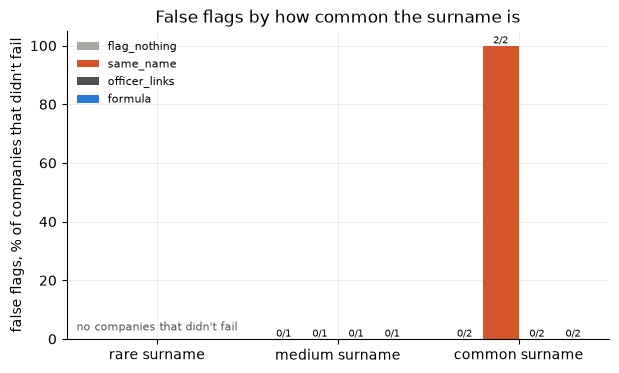

,method,band,companies,not_failed,flags,false_flags,false_flag_rate
0,flag_nothing,rare,0,0,0,0,NaN
1,flag_nothing,medium,1,1,0,0,0.0
2,flag_nothing,common,3,2,0,0,0.0
3,same_name,rare,0,0,0,0,NaN
4,same_name,medium,1,1,0,0,0.0
5,same_name,common,3,2,3,2,1.0
6,officer_links,rare,0,0,0,0,NaN
7,officer_links,medium,1,1,0,0,0.0
8,officer_links,common,3,2,0,0,0.0
9,formula,rare,0,0,0,0,NaN


In [15]:
# 108: false flags per name-commonness band, for ours and the three baselines, with the counts on the bars.
bands = evaluate.company_bands(mentions, claims, evaluate.name_commonness(mentions))
by_band = evaluate.false_flags_by_band(all_decisions, labels, bands)
interface.display_png(interface.false_flag_figure(by_band))
by_band

*Each bar is false flags out of the companies in that band that didn't fail. Our main claim is that the same-name rule's bar grows with how common the surname is, and ours doesn't.*

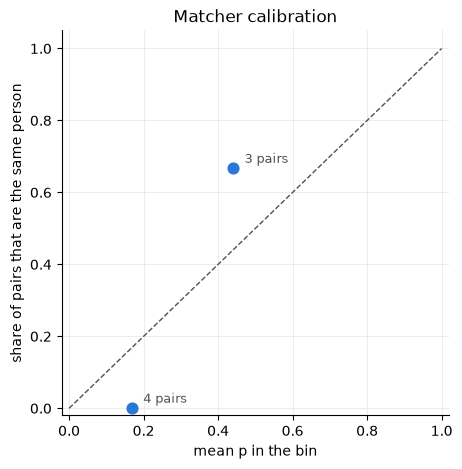

In [16]:
# 108: is the matcher's p a probability? Its p against the share of pairs that are the same person.
# Tiny world: these are the matcher's own training pairs, so this only checks that the plot draws.
interface.display_png(interface.reliability_figure(scored["p"], scored["label"]))

*On the dashed line, p means what it says: of the pairs given about 0.6, about 60% are the same person. The number next to each dot is how many pairs it rests on.*

## Demo
One company number in, the result out. This is the tiny world's phoenix, with the stand-in probabilities from the Model section.

In [14]:
answer = our_decisions.set_index("query").loc["TW000002"]
print("(tiny world, stand-in probabilities: a pipeline check, not a result)")
print(answer["decision"])
print(answer["reason"])

(tiny world, stand-in probabilities: a pipeline check, not a result)
FLAG
TW000002 may share a director with TW000001, an earlier company that went insolvent (an estimated 90% chance it's the same person): its 90% chance of failing within two years is high enough to flag. This becomes CLEAR if the director matched with TW000001 turns out not to be the same person.


**The picture and its evidence.** `interface.show` takes a company number and prints the decision and the reason, draws the graph and lists every line of it with its source. Solid lines are on the register; dashed lines are our guess that two records are one person, with how sure we are in words. Only the masked display columns are shown (the tiny world's names are invented, so they may be).

TW000002: FLAG
TW000002 may share a director with TW000001, an earlier company that went insolvent (an estimated 90% chance it's the same person): its 90% chance of failing within two years is high enough to flag. This becomes CLEAR if the director matched with TW000001 turns out not to be the same person.
Check first: match 0 (with TW000001). The decision becomes CLEAR if it is not the same person: try what_if(..., reject=[0]).


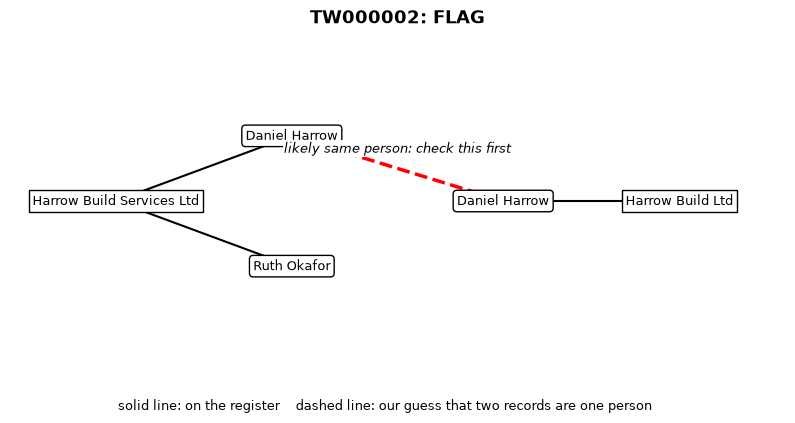

,line,from,to,says,how sure,p,source,record or depends on,check first
0,solid (fact),Daniel Harrow,Harrow Build Services Ltd,director of,on the register,NaN,tiny_world,tests/tiny_world.py#1@ef7c706d037dd9f2149c88bb...,
1,solid (fact),Ruth Okafor,Harrow Build Services Ltd,director of,on the register,NaN,tiny_world,tests/tiny_world.py#7@f47e303cf37f750eb75a9354...,
2,solid (fact),Daniel Harrow,Harrow Build Ltd,director of,on the register,NaN,tiny_world,tests/tiny_world.py#0@cdb8e20e70b82d41200a6f41...,
3,dashed (guess),Daniel Harrow,Daniel Harrow,same person?,likely,0.9,our matcher,"4f161e287f64c292, 0bf795f12d21c59c",yes


In [15]:
from src import interface

row, fig, table = interface.show("TW000002", mentions, claims, matches, our_decisions)

In [16]:
# A company outside our data gets a polite answer, not an error
interface.show("00000006", mentions, claims, matches, our_decisions)

Sorry, 00000006 isn't one of the companies we have data for, so we can't judge it. Check the number: we cover construction companies (SIC 41-43) formed in 2021 and 2022.


**What if someone checks the match by hand?** The flag rests on one guess: that the two Daniel Harrows are the same person. `interface.what_if` lets a person confirm a match (p becomes 1) or reject it (p becomes 0); every other match stays as it was. Then the decision layer runs again.

In [17]:
# Match 0 is the first dashed row of the evidence table above
checked = interface.what_if(matches["TW000002"], reject=[0])
after = decide.decide("TW000002", checked, line, costs)

print("before:", row["decision"], "   after rejecting match 0:", after["decision"])
print(after["reason"])

before: FLAG    after rejecting match 0: CLEAR
TW000002 may share a director with TW000001, an earlier company that went insolvent (an estimated 0% chance it's the same person): its 0% chance of failing within two years is low enough to clear. This becomes FLAG if the director matched with TW000001 turns out to be the same person.


**What if the costs were different?** The thresholds come from three costs the team chose: a missed case 10, a wrong flag 2, asking someone to check 1. Move a slider to see the thresholds and the decision move; Reset goes back to the agreed costs. Sliders only work when the notebook runs, so the line below them shows the agreed costs for anyone reading it on GitHub.

In [18]:
interface.cost_sliders("TW000002", matches["TW000002"], line, costs, decide.decide, decide.thresholds)

Costs: missed case 10, wrong flag 2, asking 1. Clear at or below 10%, flag at or above 50%. TW000002: FLAG
